# Week 3: Volatility
Treating volatility as a static constant is the most common beginner error.

In [14]:
# Load your data from ../data/ (see the setup notebook)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.signal import find_peaks
from statsmodels.tsa.stattools import acf  

TICKERS = ["SPY", "RSP"]    # <- change to your pair (exact Yahoo Finance tickers)
SPY_prices = pd.read_csv(f"../data/{TICKERS[0]}.csv", index_col=0, parse_dates=True)
RSP_prices = pd.read_csv(f"../data/{TICKERS[1]}.csv", index_col=0, parse_dates=True)
SPY_prices.tail() #view last 5 rows as an example


daily_ret_SPY = SPY_prices['Adj Close'].pct_change().dropna()
daily_ret_RSP = RSP_prices['Adj Close'].pct_change().dropna()
print(daily_ret_SPY.head()) #view first 5 rows as an example


returns = pd.concat([daily_ret_SPY, daily_ret_RSP], axis=1, join="inner" ).dropna()
returns.columns = ["SPY_ret", "RSP_ret"]

print(returns.head())
print(returns.shape)

Date
2016-01-05    0.001691
2016-01-06   -0.012614
2016-01-07   -0.023992
2016-01-08   -0.010977
2016-01-11    0.000990
Name: Adj Close, dtype: float64
             SPY_ret   RSP_ret
Date                          
2016-01-05  0.001691  0.002375
2016-01-06 -0.012614 -0.018297
2016-01-07 -0.023992 -0.022660
2016-01-08 -0.010977 -0.012210
2016-01-11  0.000990 -0.003194
(2513, 2)


## Visual
Plot the **21-day rolling annualized volatility** for both assets. Mark the **three highest spikes** and
identify the real-world events that caused them. (You'll have to calculate it from returns which you found in week 1)

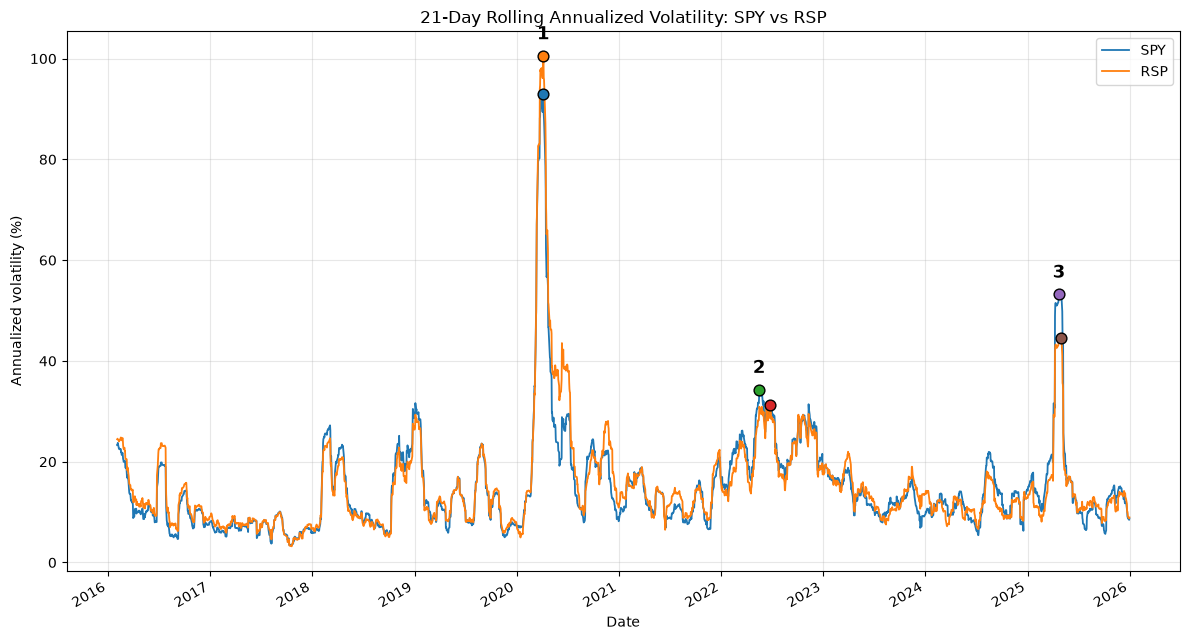

Spike 1 SPY_ret: 2020-04-06  93.0%
Spike 1 RSP_ret: 2020-04-06  100.5%
Spike 2 SPY_ret: 2022-05-18  34.3%
Spike 2 RSP_ret: 2022-06-24  31.2%
Spike 3 SPY_ret: 2025-04-24  53.2%
Spike 3 RSP_ret: 2025-05-02  44.5%


In [20]:
# 21-day rolling standard deviation of daily returns, annualized with sqrt(252)
vol = (returns.rolling(21).std() * np.sqrt(252)).dropna()
# print(vol.head())

# The three highest raw values are consecutive days in one crisis, so find distinct
# episodes instead: peaks at least 126 trading days (about 6 months) apart
pk, _ = find_peaks(vol["SPY_ret"].values, distance=126)
top3 = vol["SPY_ret"].iloc[pk].nlargest(3).index.sort_values()


fig, ax = plt.subplots(figsize=(12, 6.5))
vol["SPY_ret"].mul(100).plot(ax=ax, lw=1.3, label="SPY")
vol["RSP_ret"].mul(100).plot(ax=ax, lw=1.3, label="RSP")

for n, anchor in enumerate(top3, start=1):
    i = vol.index.get_loc(anchor)
    for t in ["SPY_ret", "RSP_ret"]:
        # each asset's own peak within +/-30 trading days of the episode
        w = vol[t].iloc[max(0, i - 30): i + 31]
        ax.scatter(w.idxmax(), w.max() * 100, s=60, edgecolor="black", zorder=5)
    top_y = max(vol[t].iloc[max(0, i - 30): i + 31].max() for t in ["SPY_ret", "RSP_ret"]) * 100
    ax.annotate(str(n), (anchor, top_y), xytext=(0, 12), textcoords="offset points",
                ha="center", fontsize=13, fontweight="bold")

ax.set_title("21-Day Rolling Annualized Volatility: SPY vs RSP")
ax.set_ylabel("Annualized volatility (%)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

for n, anchor in enumerate(top3, start=1):
      i = vol.index.get_loc(anchor)
      for t in ["SPY_ret", "RSP_ret"]:
          w = vol[t].iloc[max(0, i - 30): i + 31]
          print(f"Spike {n} {t}: {w.idxmax().date()}  {w.max():.1%}")

| Asset | Spike date | Event |
|---|---|---|
| SPY/RSP | 2020-04-06 | A relief rally in the middle of the COVID crash |
| SPY | 2022-05-18 | The S&P 500 fell 4%, its worst day since June 2020, a sharp selloff after Target’s earnings miss |
| SPY | 2025-04-24 | A calm-looking rally on trade-deal hopes, but it came after a month of huge swings |
| RSP | 2022-06-24 | peak came on a day SPY and RSP both rose about 3.2%. The volatility reading was high because the window contained the mid-June selloff |
| RSP | 2025-05-02 | RSP gained 1.76% (SPY +1.48%). Its window still held the April 4 and 9 moves |

## The Check
Test for volatility clustering by plotting the **autocorrelation of absolute returns**
(proving that "big days follow big days").

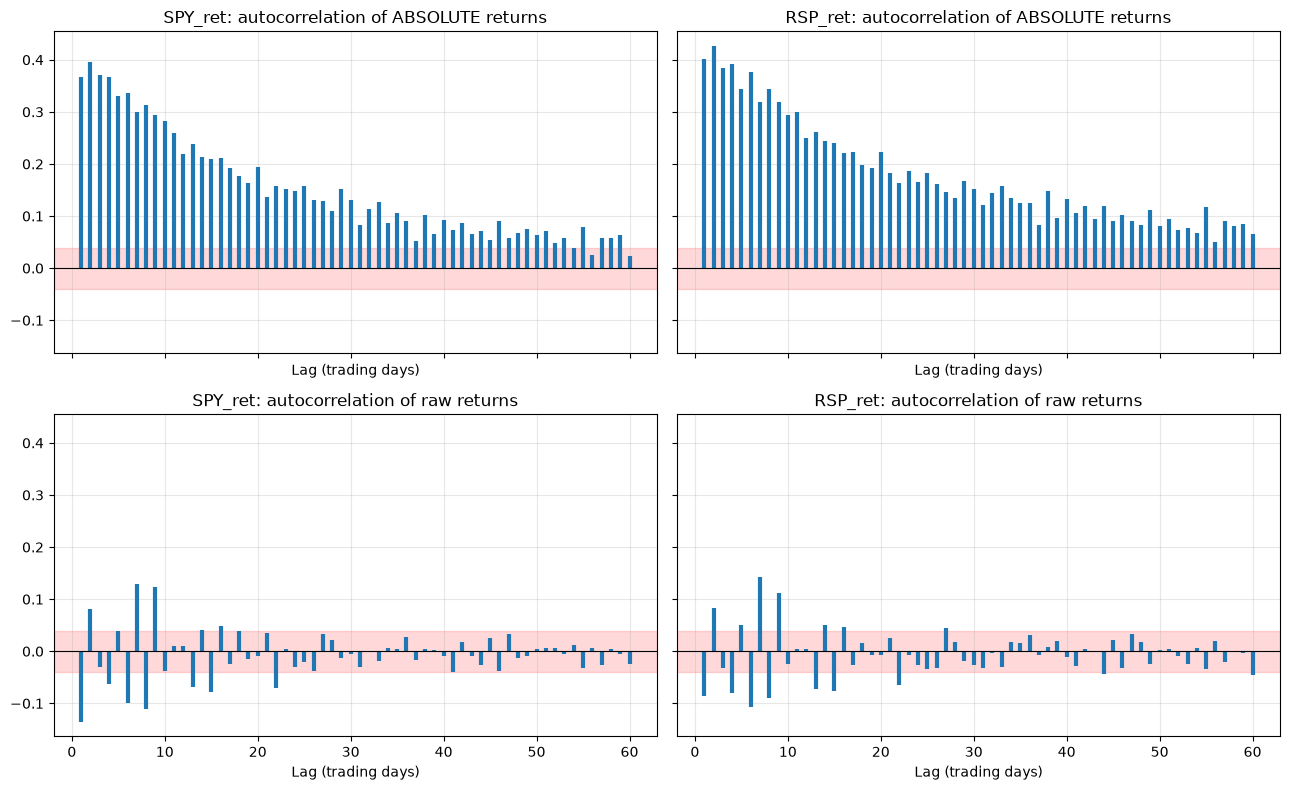

In [17]:
LAGS = 60
band = 1.96 / np.sqrt(len(returns))                 # 95% band: values inside are consistent with zero autocorrelation

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
lags = np.arange(1, LAGS + 1)

for j, tk in enumerate(["SPY_ret", "RSP_ret"]):
    r = returns[tk]
    # top row: absolute returns (size of the move); bottom row: raw returns (signed) for contrast
    for i, (series, title) in enumerate([(r.abs(), "ABSOLUTE returns"), (r, "raw returns")]):
        a = acf(series, nlags=LAGS, fft=True)       # a[0] is always 1, so plot from lag 1
        ax = axes[i, j]
        ax.vlines(lags, 0, a[1:], lw=3)
        ax.axhspan(-band, band, color="red", alpha=0.15)   # shaded band = "no autocorrelation"
        ax.axhline(0, color="black", lw=0.8)
        ax.set_title(f"{tk}: autocorrelation of {title}")
        ax.set_xlabel("Lag (trading days)")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## The Paragraph
> **Does market panic hit both assets simultaneously, or do they experience isolated crises?**

Market panic hit both assets simultaneously. SPY and RSP had a daily return correlation of 0.94 over the ten years, and it rose to 0.98 during the highest-volatility periods (against 0.87 in the calmest half), so diversification between the two disappeared when it was most needed. Their 21-day volatility series moved almost in lockstep (correlation 0.97), and all three major spikes (the COVID crash in 2020, the inflation and rate-hike selloff of 2022, and the tariff shock of 2025) appeared in both assets within weeks of each other. Of the 126 worst days (the worst 5%) for each fund, 100 were common to both. The two did differ in magnitude, not in timing: RSP’s volatility reached 100.5% in April 2020 against SPY’s 93.0%, but fell short of SPY in 2025 (44.5% against 53.2%). That likely reflects RSP’s heavier exposure to cyclical stocks in the pandemic and SPY’s concentration in large tech during the tariff shock. Crises in this pair were therefore shared, with only the size of the damage differing between the two funds.

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 6: volatility"
git push
```